# LeafletFA Imputation Evaluation

Summarizes per-junction Pearson imputation results from `04c_evaluate_imputation_perjunc.py`.

**Methods compared:**
- `lf` — raw `phi @ psi` (LeafletFA prior only, no observed data)
- `lf_bb` — Beta-Binomial posterior mean combining LeafletFA prior with observed counts
- `mb` — MeanBayes (population-level Beta prior + observed counts)
- `naive` — per-junction mean across observed cells (sanity check, should score ~0)

**Metric:** Per-junction Pearson across cells (ranks cells correctly for each HVJ junction).
Evaluated on top 10k highly variable junctions (HVJ) with ATSE > 30 in original data.

In [1]:
import pandas as pd
import numpy as np
import glob
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

plt.rcParams.update({'font.size': 11, 'figure.dpi': 120})
sns.set_style('whitegrid')

EVAL_DIR = ('/gpfs/commons/groups/knowles_lab/Karin/Leaflet-analysis-WD/'
            'MOUSE_SPLICING_FOUNDATION/LEAFLETFA_MODELS/2026-06-18/eval_results_perjunc_bb')

METHOD_COLS = ['median_pearson_lf', 'median_pearson_lf_bb',
               'median_pearson_mb', 'median_pearson_naive']
FRAC_COLS   = ['frac_r_gt_03_lf', 'frac_r_gt_03_lf_bb',
               'frac_r_gt_03_mb', 'frac_r_gt_03_naive']
FRAC05_COLS = ['frac_r_gt_05_lf', 'frac_r_gt_05_lf_bb',
               'frac_r_gt_05_mb', 'frac_r_gt_05_naive']

METHOD_LABELS = {
    'median_pearson_lf':     'LeafletFA (phi@psi)',
    'median_pearson_lf_bb':  'LeafletFA BB posterior',
    'median_pearson_mb':     'MeanBayes',
    'median_pearson_naive':  'Naive mean',
    'frac_r_gt_03_lf':       'LeafletFA (phi@psi)',
    'frac_r_gt_03_lf_bb':    'LeafletFA BB posterior',
    'frac_r_gt_03_mb':       'MeanBayes',
    'frac_r_gt_03_naive':    'Naive mean',
    'frac_r_gt_05_lf':       'LeafletFA (phi@psi)',
    'frac_r_gt_05_lf_bb':    'LeafletFA BB posterior',
    'frac_r_gt_05_mb':       'MeanBayes',
    'frac_r_gt_05_naive':    'Naive mean',
}
METHOD_COLORS = {
    'LeafletFA (phi@psi)':    '#d62728',
    'LeafletFA BB posterior': '#1f77b4',
    'MeanBayes':              '#2ca02c',
    'Naive mean':             '#7f7f7f',
}

csvs = glob.glob(f'{EVAL_DIR}/run_*_perjunc_hvj10000_atse30_results.csv')
df = pd.concat([pd.read_csv(f) for f in csvs], ignore_index=True)
print(f'Runs: {df["run_dir"].nunique()}  |  Rows: {len(df)}')
print(f'Datasets: {sorted(df["dataset"].unique())}')
print(f'K values: {sorted(df["K"].unique())}')
print(f'Downsampling pcts: {sorted(df["downsampling_pct"].unique())}')
df.head(2)

Runs: 70  |  Rows: 1470
Datasets: ['all', 'allen_brain_exons', 'tabula_muris_senis']
K values: [5, 10, 20, 50]
Downsampling pcts: [10, 25, 50, 75, 90, 99, 100]


,run_dir,param_id,K,pruned_K,waypoints_use,junc_specific_prior,batch_size,best_elbo,downsampling_pct,n_hvj,...,frac_r_gt_03_mb,frac_r_gt_05_mb,median_pearson_naive,mean_pearson_naive,frac_r_gt_03_naive,frac_r_gt_05_naive,global_pearson_lf,global_pearson_lf_bb,global_pearson_mb,n_cells
0,run_47,47,50,50,False,False,8192,1.188853e+08,10,10000,...,0.999493,0.999493,0.0,0.0,0.0,0.0,0.388499,0.992804,0.992811,39812
1,run_47,47,50,50,False,False,8192,1.188853e+08,10,10000,...,0.999476,0.999476,0.0,0.0,0.0,0.0,0.197449,0.968774,0.968496,16371


## 1. Overall: median per-junction Pearson vs downsampling

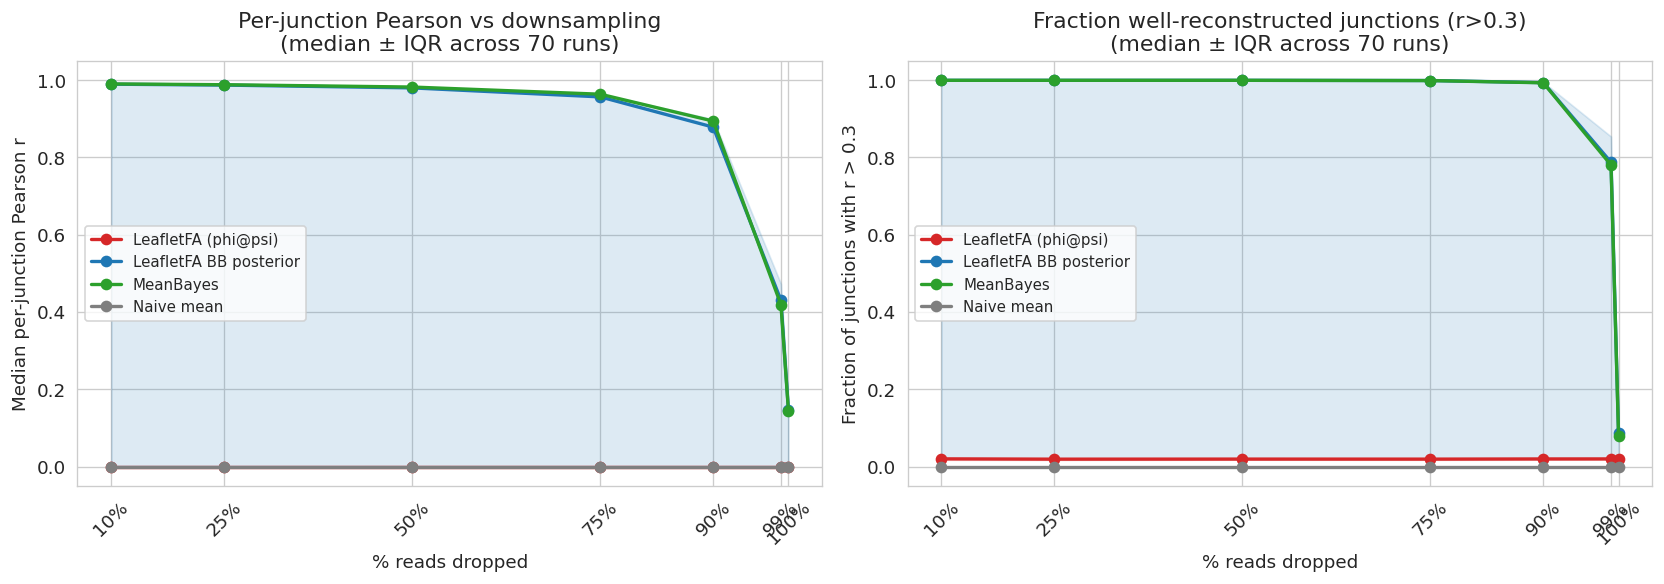

In [2]:
all_df = df[df['dataset'] == 'all'].copy()
pcts = sorted(all_df['downsampling_pct'].unique())
pct_labels = [f'{p}%' for p in pcts]

# Compute median and IQR across runs per downsampling level
summary = all_df.groupby('downsampling_pct')[METHOD_COLS].agg(['median', lambda x: x.quantile(0.25), lambda x: x.quantile(0.75)])
summary.columns = ['_'.join(c) for c in summary.columns]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: median per-junction Pearson
ax = axes[0]
for col in METHOD_COLS:
    label = METHOD_LABELS[col]
    color = METHOD_COLORS[label]
    med  = all_df.groupby('downsampling_pct')[col].median()
    q25  = all_df.groupby('downsampling_pct')[col].quantile(0.25)
    q75  = all_df.groupby('downsampling_pct')[col].quantile(0.75)
    ax.plot(pcts, med.values, marker='o', label=label, color=color, lw=2)
    ax.fill_between(pcts, q25.values, q75.values, alpha=0.15, color=color)

ax.set_xlabel('% reads dropped')
ax.set_ylabel('Median per-junction Pearson r')
ax.set_title('Per-junction Pearson vs downsampling\n(median ± IQR across 70 runs)')
ax.set_xticks(pcts); ax.set_xticklabels(pct_labels, rotation=45)
ax.legend(fontsize=9)
ax.set_ylim(-0.05, 1.05)

# Panel B: frac junctions with r > 0.3
ax = axes[1]
for col in FRAC_COLS:
    label = METHOD_LABELS[col]
    color = METHOD_COLORS[label]
    med = all_df.groupby('downsampling_pct')[col].median()
    q25 = all_df.groupby('downsampling_pct')[col].quantile(0.25)
    q75 = all_df.groupby('downsampling_pct')[col].quantile(0.75)
    ax.plot(pcts, med.values, marker='o', label=label, color=color, lw=2)
    ax.fill_between(pcts, q25.values, q75.values, alpha=0.15, color=color)

ax.set_xlabel('% reads dropped')
ax.set_ylabel('Fraction of junctions with r > 0.3')
ax.set_title('Fraction well-reconstructed junctions (r>0.3)\n(median ± IQR across 70 runs)')
ax.set_xticks(pcts); ax.set_xticklabels(pct_labels, rotation=45)
ax.legend(fontsize=9)
ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/fig_overall_pearson_vs_downsampling.pdf', bbox_inches='tight')
plt.show()

## 2. lf_bb vs MeanBayes: advantage at high dropout

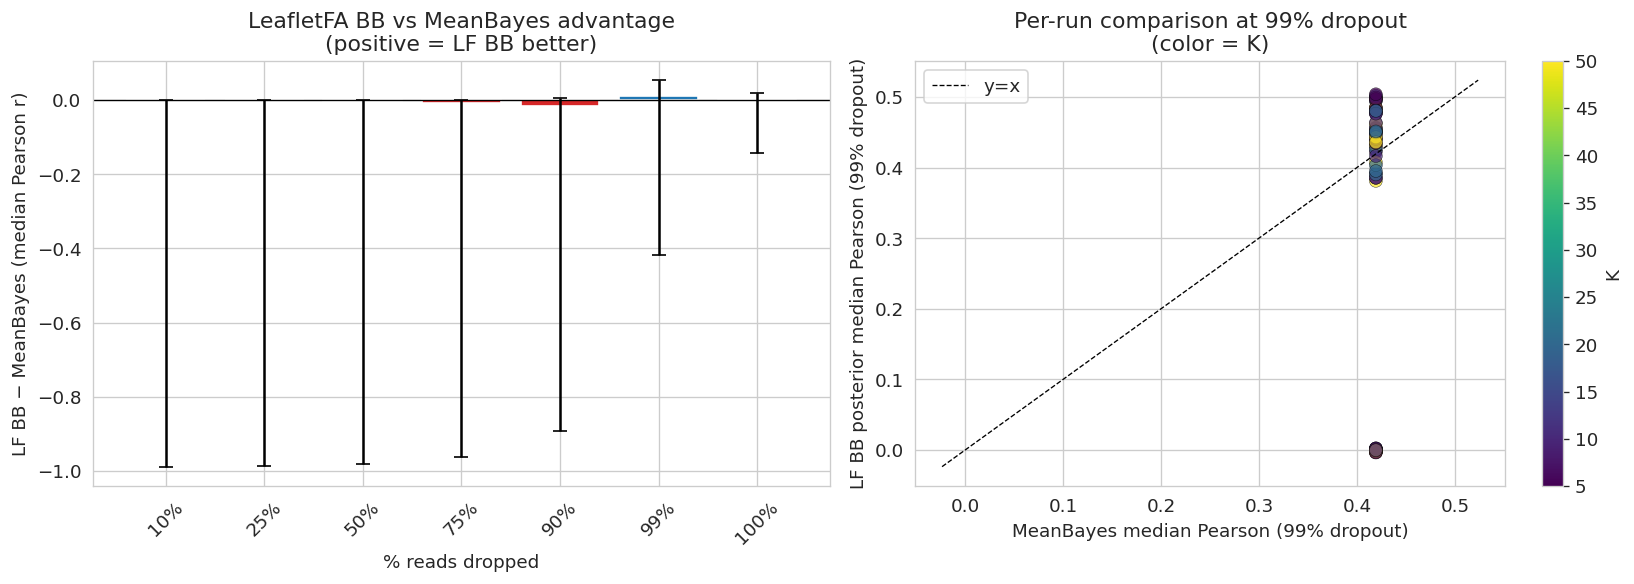

Delta lf_bb - mb (median across runs):
downsampling_pct
10    -0.00067
25    -0.00099
50    -0.00222
75    -0.00700
90    -0.01564
99     0.01124
100    0.00275
Name: delta_lf_bb_vs_mb, dtype: float64


In [3]:
# Delta: lf_bb - mb  (positive = LF BB better)
all_df = all_df.copy()
all_df['delta_lf_bb_vs_mb'] = all_df['median_pearson_lf_bb'] - all_df['median_pearson_mb']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel A: delta across downsampling
ax = axes[0]
delta_med = all_df.groupby('downsampling_pct')['delta_lf_bb_vs_mb'].median()
delta_q25 = all_df.groupby('downsampling_pct')['delta_lf_bb_vs_mb'].quantile(0.25)
delta_q75 = all_df.groupby('downsampling_pct')['delta_lf_bb_vs_mb'].quantile(0.75)
ax.bar(range(len(pcts)), delta_med.values, color=['#1f77b4' if v >= 0 else '#d62728' for v in delta_med.values])
ax.errorbar(range(len(pcts)), delta_med.values,
            yerr=[delta_med.values - delta_q25.values, delta_q75.values - delta_med.values],
            fmt='none', color='black', capsize=4)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(range(len(pcts))); ax.set_xticklabels(pct_labels, rotation=45)
ax.set_xlabel('% reads dropped')
ax.set_ylabel('LF BB − MeanBayes (median Pearson r)')
ax.set_title('LeafletFA BB vs MeanBayes advantage\n(positive = LF BB better)')

# Panel B: per-run scatter at 99% dropout
ax = axes[1]
d99 = all_df[all_df['downsampling_pct'] == 99]
ax.scatter(d99['median_pearson_mb'], d99['median_pearson_lf_bb'],
           c=d99['K'], cmap='viridis', alpha=0.7, edgecolors='k', lw=0.3, s=60)
lims = [min(d99['median_pearson_mb'].min(), d99['median_pearson_lf_bb'].min()) - 0.02,
        max(d99['median_pearson_mb'].max(), d99['median_pearson_lf_bb'].max()) + 0.02]
ax.plot(lims, lims, 'k--', lw=0.8, label='y=x')
ax.set_xlabel('MeanBayes median Pearson (99% dropout)')
ax.set_ylabel('LF BB posterior median Pearson (99% dropout)')
ax.set_title('Per-run comparison at 99% dropout\n(color = K)')
sc = ax.scatter([], [], c=[], cmap='viridis')
plt.colorbar(plt.cm.ScalarMappable(cmap='viridis',
    norm=plt.Normalize(d99['K'].min(), d99['K'].max())), ax=ax, label='K')
ax.legend()

plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/fig_lf_bb_vs_mb_advantage.pdf', bbox_inches='tight')
plt.show()

print('Delta lf_bb - mb (median across runs):')
print(all_df.groupby('downsampling_pct')['delta_lf_bb_vs_mb'].median().round(5))

## 3. By model type: K, waypoints, junc_specific_prior

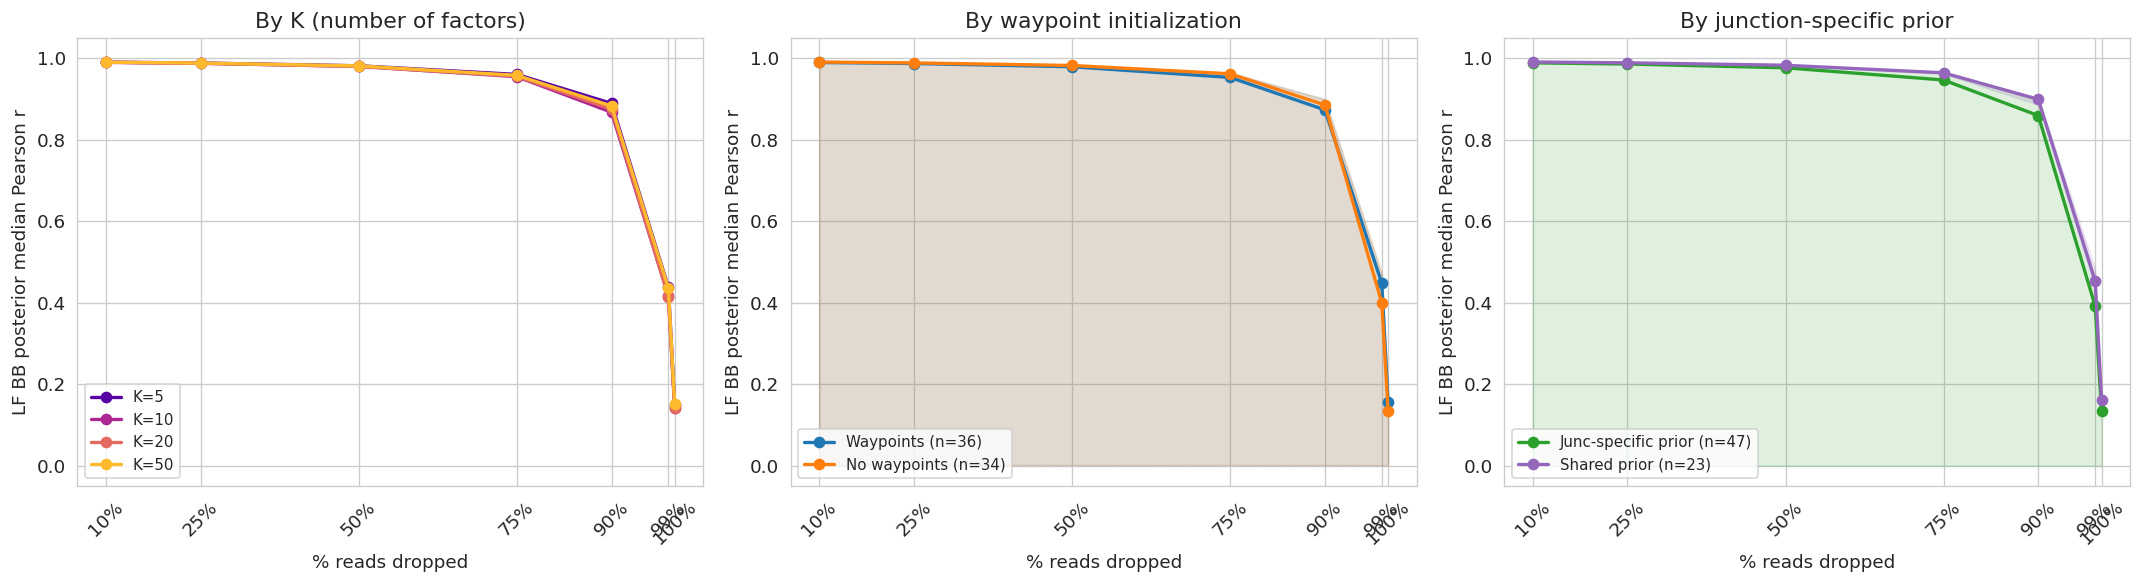

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
focus_col = 'median_pearson_lf_bb'
focus_label = 'LF BB posterior median Pearson r'

# Panel A: by K
ax = axes[0]
k_vals = sorted(all_df['K'].unique())
colors_k = plt.cm.plasma(np.linspace(0.15, 0.85, len(k_vals)))
for K, color in zip(k_vals, colors_k):
    sub = all_df[all_df['K'] == K]
    med = sub.groupby('downsampling_pct')[focus_col].median()
    ax.plot(pcts, med.values, marker='o', label=f'K={K}', color=color, lw=2)
ax.set_xlabel('% reads dropped'); ax.set_ylabel(focus_label)
ax.set_title('By K (number of factors)')
ax.set_xticks(pcts); ax.set_xticklabels(pct_labels, rotation=45)
ax.legend(fontsize=9); ax.set_ylim(-0.05, 1.05)

# Panel B: by waypoints_use
ax = axes[1]
for wp, color, label in [(True, '#1f77b4', 'Waypoints'), (False, '#ff7f0e', 'No waypoints')]:
    sub = all_df[all_df['waypoints_use'] == wp]
    if len(sub) == 0: continue
    med = sub.groupby('downsampling_pct')[focus_col].median()
    q25 = sub.groupby('downsampling_pct')[focus_col].quantile(0.25)
    q75 = sub.groupby('downsampling_pct')[focus_col].quantile(0.75)
    ax.plot(pcts, med.values, marker='o', label=f'{label} (n={sub["run_dir"].nunique()})',
            color=color, lw=2)
    ax.fill_between(pcts, q25.values, q75.values, alpha=0.15, color=color)
ax.set_xlabel('% reads dropped'); ax.set_ylabel(focus_label)
ax.set_title('By waypoint initialization')
ax.set_xticks(pcts); ax.set_xticklabels(pct_labels, rotation=45)
ax.legend(fontsize=9); ax.set_ylim(-0.05, 1.05)

# Panel C: by junc_specific_prior
ax = axes[2]
for jsp, color, label in [(True, '#2ca02c', 'Junc-specific prior'), (False, '#9467bd', 'Shared prior')]:
    sub = all_df[all_df['junc_specific_prior'] == jsp]
    if len(sub) == 0: continue
    med = sub.groupby('downsampling_pct')[focus_col].median()
    q25 = sub.groupby('downsampling_pct')[focus_col].quantile(0.25)
    q75 = sub.groupby('downsampling_pct')[focus_col].quantile(0.75)
    ax.plot(pcts, med.values, marker='o', label=f'{label} (n={sub["run_dir"].nunique()})',
            color=color, lw=2)
    ax.fill_between(pcts, q25.values, q75.values, alpha=0.15, color=color)
ax.set_xlabel('% reads dropped'); ax.set_ylabel(focus_label)
ax.set_title('By junction-specific prior')
ax.set_xticks(pcts); ax.set_xticklabels(pct_labels, rotation=45)
ax.legend(fontsize=9); ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/fig_by_model_type.pdf', bbox_inches='tight')
plt.show()

## 4. By dataset: allen_brain_exons vs tabula_muris_senis

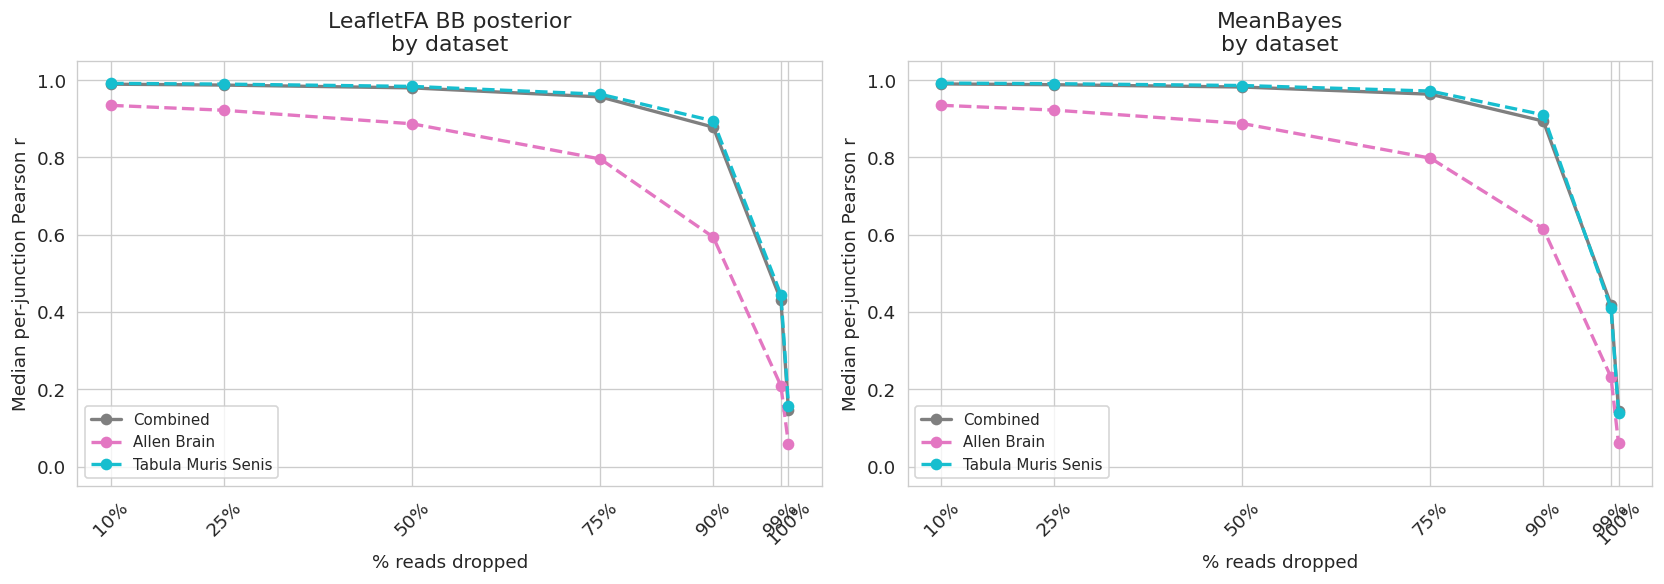


=== median_pearson_lf_bb by dataset and downsampling ===
downsampling_pct      10     25     50     75     90     99     100
dataset                                                            
all                 0.990  0.987  0.980  0.957  0.878  0.431  0.147
allen_brain_exons   0.935  0.922  0.887  0.796  0.594  0.209  0.059
tabula_muris_senis  0.992  0.990  0.984  0.964  0.895  0.445  0.158


In [5]:
datasets = ['allen_brain_exons', 'tabula_muris_senis']
ds_colors = {'allen_brain_exons': '#e377c2', 'tabula_muris_senis': '#17becf', 'all': '#7f7f7f'}
ds_labels = {'allen_brain_exons': 'Allen Brain', 'tabula_muris_senis': 'Tabula Muris Senis', 'all': 'Combined'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, col, title in zip(axes,
    ['median_pearson_lf_bb', 'median_pearson_mb'],
    ['LeafletFA BB posterior', 'MeanBayes']):

    for ds in ['all'] + datasets:
        sub = df[df['dataset'] == ds]
        med = sub.groupby('downsampling_pct')[col].median()
        ls = '-' if ds == 'all' else '--'
        ax.plot(pcts, med.values, marker='o', label=ds_labels[ds],
                color=ds_colors[ds], lw=2, ls=ls)

    ax.set_xlabel('% reads dropped')
    ax.set_ylabel('Median per-junction Pearson r')
    ax.set_title(f'{title}\nby dataset')
    ax.set_xticks(pcts); ax.set_xticklabels(pct_labels, rotation=45)
    ax.legend(fontsize=9); ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/fig_by_dataset.pdf', bbox_inches='tight')
plt.show()

# Summary table
print('\n=== median_pearson_lf_bb by dataset and downsampling ===')
print(df.groupby(['dataset','downsampling_pct'])['median_pearson_lf_bb'].median().unstack().round(3).to_string())

## 5. Waypoint initialization: psi and phi delta

Waypoint runs with delta: 36


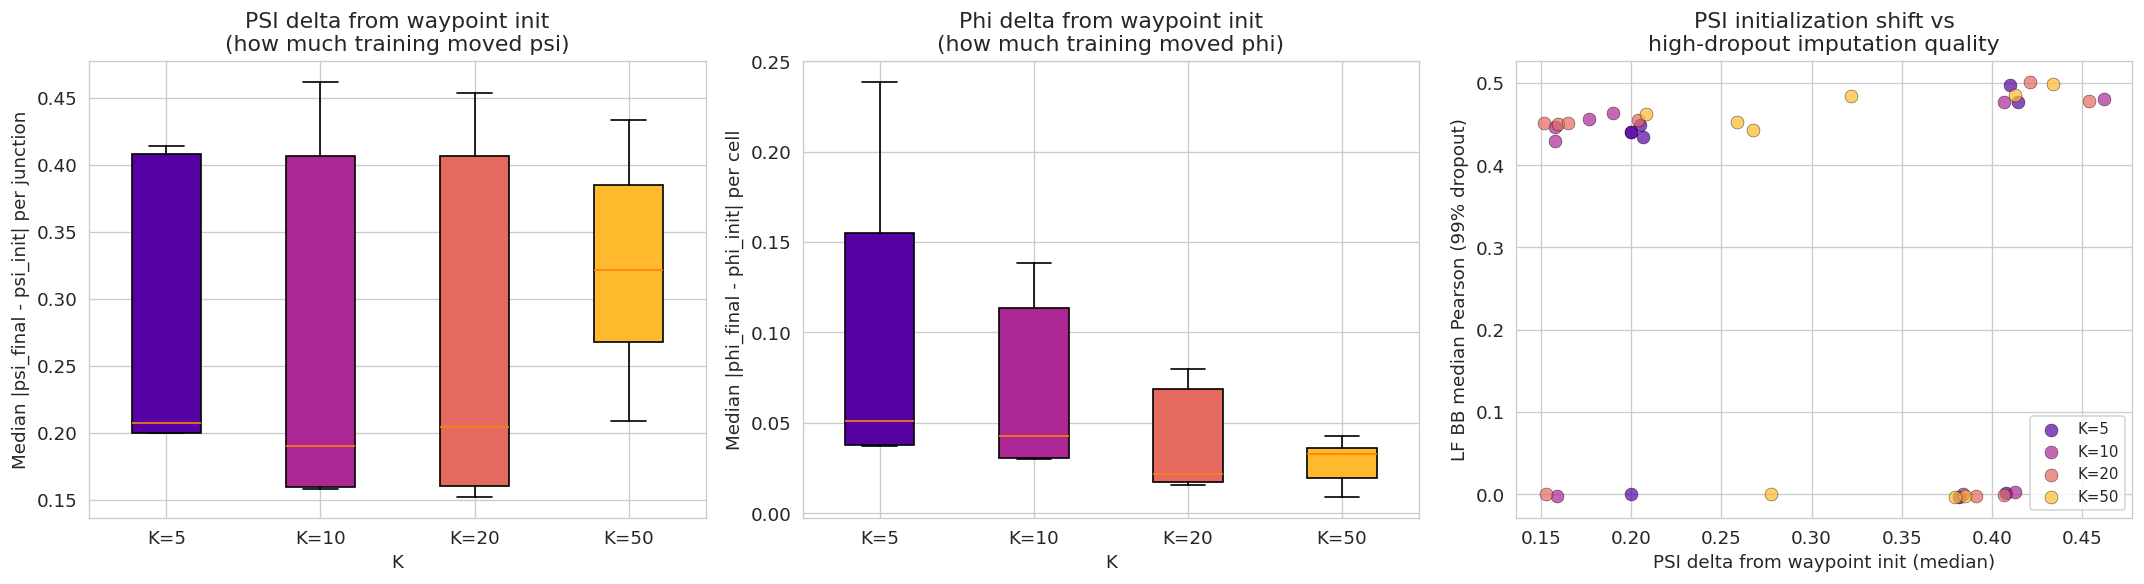


PSI / phi delta summary by K:
    delta_psi_median  delta_psi_p95  delta_phi_median  delta_phi_p95
K                                                                   
5             0.2068         0.5137            0.0508         0.0712
10            0.1903         0.4799            0.0425         0.0607
20            0.2039         0.4456            0.0220         0.0315
50            0.3217         0.5414            0.0325         0.0355


In [6]:
wp_df = all_df[(all_df['waypoints_use'] == True) & all_df['delta_psi_median'].notna()].copy()
# One row per run (take 10% dropout slice for run-level metrics)
run_df = wp_df[wp_df['downsampling_pct'] == 10].copy()
print(f'Waypoint runs with delta: {len(run_df)}')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: psi delta by K
ax = axes[0]
k_vals = sorted(run_df['K'].unique())
data_by_k = [run_df[run_df['K'] == k]['delta_psi_median'].values for k in k_vals]
bp = ax.boxplot(data_by_k, labels=[f'K={k}' for k in k_vals], patch_artist=True)
for patch, color in zip(bp['boxes'], plt.cm.plasma(np.linspace(0.15, 0.85, len(k_vals)))):
    patch.set_facecolor(color)
ax.set_xlabel('K'); ax.set_ylabel('Median |psi_final - psi_init| per junction')
ax.set_title('PSI delta from waypoint init\n(how much training moved psi)')

# Panel B: phi delta by K
ax = axes[1]
data_by_k_phi = [run_df[run_df['K'] == k]['delta_phi_median'].values for k in k_vals]
bp = ax.boxplot(data_by_k_phi, labels=[f'K={k}' for k in k_vals], patch_artist=True)
for patch, color in zip(bp['boxes'], plt.cm.plasma(np.linspace(0.15, 0.85, len(k_vals)))):
    patch.set_facecolor(color)
ax.set_xlabel('K'); ax.set_ylabel('Median |phi_final - phi_init| per cell')
ax.set_title('Phi delta from waypoint init\n(how much training moved phi)')

# Panel C: delta psi vs imputation quality at 99% dropout
ax = axes[2]
wp99 = wp_df[wp_df['downsampling_pct'] == 99]
k_map = {k: c for k, c in zip(k_vals, plt.cm.plasma(np.linspace(0.15, 0.85, len(k_vals))))}
for k in k_vals:
    sub = wp99[wp99['K'] == k]
    ax.scatter(sub['delta_psi_median'], sub['median_pearson_lf_bb'],
               color=k_map[k], label=f'K={k}', alpha=0.7, edgecolors='k', lw=0.3, s=60)
ax.set_xlabel('PSI delta from waypoint init (median)')
ax.set_ylabel('LF BB median Pearson (99% dropout)')
ax.set_title('PSI initialization shift vs\nhigh-dropout imputation quality')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/fig_waypoint_delta.pdf', bbox_inches='tight')
plt.show()

print('\nPSI / phi delta summary by K:')
print(run_df.groupby('K')[['delta_psi_median','delta_psi_p95','delta_phi_median','delta_phi_p95']].median().round(4).to_string())

## 6. ELBO vs imputation quality

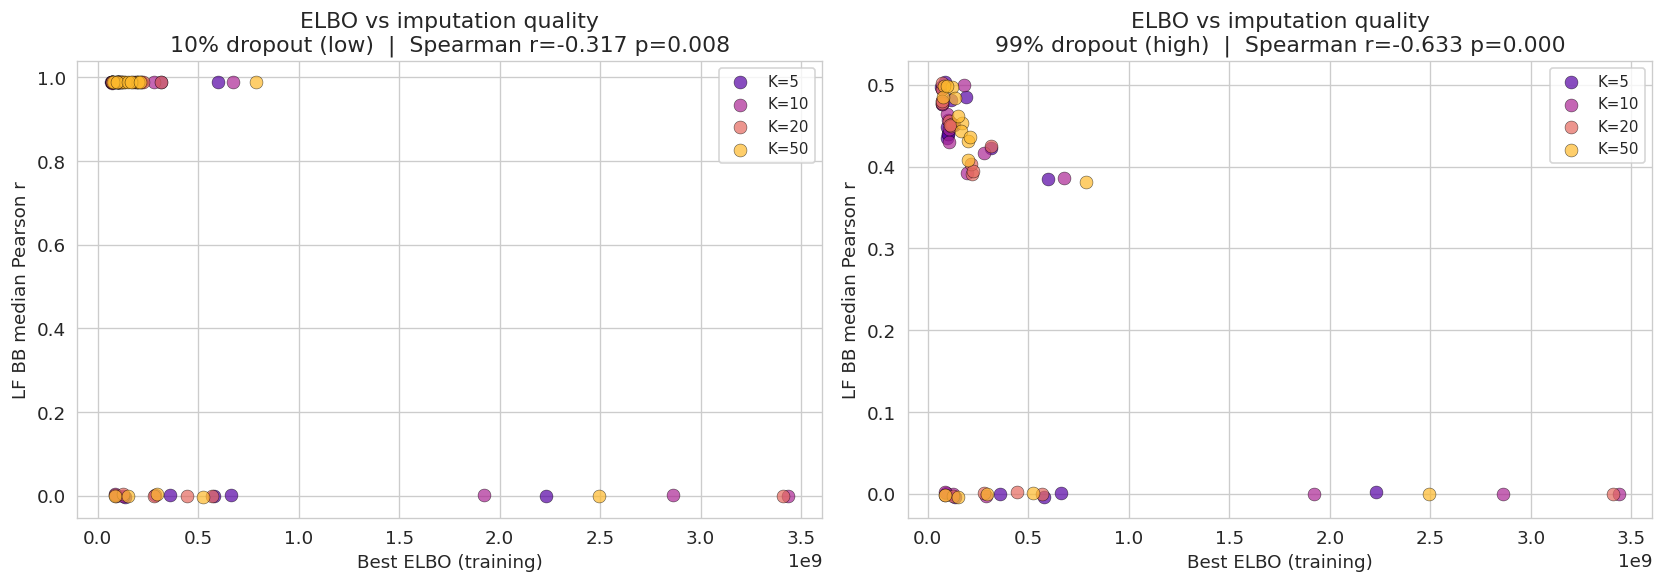

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, pct, title in zip(axes, [10, 99], ['10% dropout (low)', '99% dropout (high)']):
    sub = all_df[all_df['downsampling_pct'] == pct]
    k_vals = sorted(sub['K'].unique())
    k_map = {k: c for k, c in zip(k_vals, plt.cm.plasma(np.linspace(0.15, 0.85, len(k_vals))))}
    for k in k_vals:
        s = sub[sub['K'] == k]
        ax.scatter(s['best_elbo'], s['median_pearson_lf_bb'],
                   color=k_map[k], label=f'K={k}', alpha=0.7, edgecolors='k', lw=0.3, s=60)
    r, p = stats.spearmanr(sub['best_elbo'].dropna(), sub['median_pearson_lf_bb'].dropna())
    ax.set_xlabel('Best ELBO (training)')
    ax.set_ylabel('LF BB median Pearson r')
    ax.set_title(f'ELBO vs imputation quality\n{title}  |  Spearman r={r:.3f} p={p:.3f}')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/fig_elbo_vs_imputation.pdf', bbox_inches='tight')
plt.show()

## 7. Heatmap: full summary by model configuration

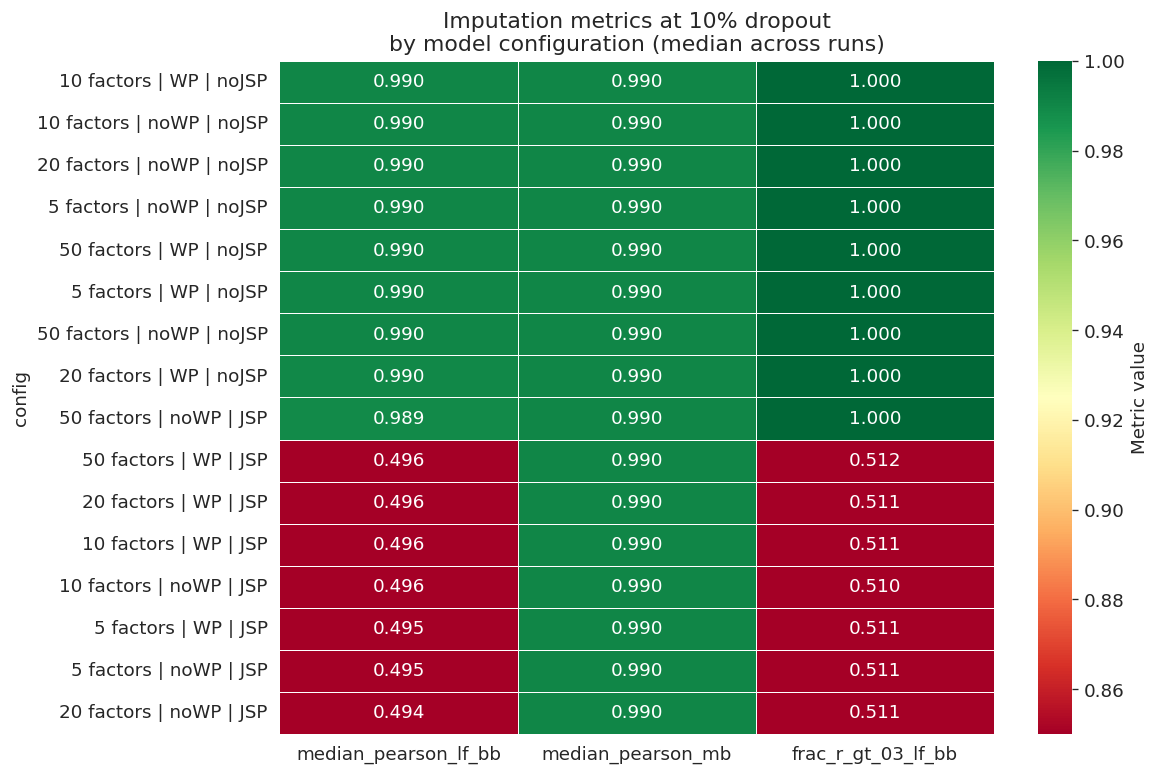


Full table:
                           median_pearson_lf_bb  median_pearson_mb  frac_r_gt_03_lf_bb
config                                                                                
10 factors | WP | noJSP                  0.9902             0.9902              0.9995
10 factors | noWP | noJSP                0.9902             0.9902              0.9995
20 factors | noWP | noJSP                0.9902             0.9902              0.9995
5 factors | noWP | noJSP                 0.9902             0.9902              0.9995
50 factors | WP | noJSP                  0.9902             0.9902              0.9995
5 factors | WP | noJSP                   0.9901             0.9902              0.9995
50 factors | noWP | noJSP                0.9901             0.9902              0.9995
20 factors | WP | noJSP                  0.9899             0.9902              0.9995
50 factors | noWP | JSP                  0.9893             0.9902              0.9995
50 factors | WP | JSP         

In [8]:
# One row per run (using 10% dropout as proxy for model quality ceiling)
run_level = all_df[all_df['downsampling_pct'] == 10][[
    'run_dir','K','waypoints_use','junc_specific_prior','batch_size','best_elbo',
    'median_pearson_lf_bb','median_pearson_mb',
    'frac_r_gt_03_lf_bb','frac_r_gt_03_mb'
]].copy()

# Label runs by config
run_level['config'] = (run_level['K'].astype(str) + ' factors | ' +
                       run_level['waypoints_use'].map({True:'WP',False:'noWP'}) + ' | ' +
                       run_level['junc_specific_prior'].map({True:'JSP',False:'noJSP'}))

# Pivot: config vs metric at 10% dropout
pivot = run_level.groupby('config')[['median_pearson_lf_bb','median_pearson_mb',
                                      'frac_r_gt_03_lf_bb']].median().round(4)
pivot = pivot.sort_values('median_pearson_lf_bb', ascending=False)

fig, ax = plt.subplots(figsize=(10, max(4, len(pivot)*0.35 + 1)))
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0.85, vmax=1.0,
            ax=ax, linewidths=0.5, cbar_kws={'label': 'Metric value'})
ax.set_title('Imputation metrics at 10% dropout\nby model configuration (median across runs)')
ax.set_xlabel('')
plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/fig_config_heatmap.pdf', bbox_inches='tight')
plt.show()

print('\nFull table:')
print(pivot.to_string())

## 8. Distribution of per-junction Pearson at key downsampling levels

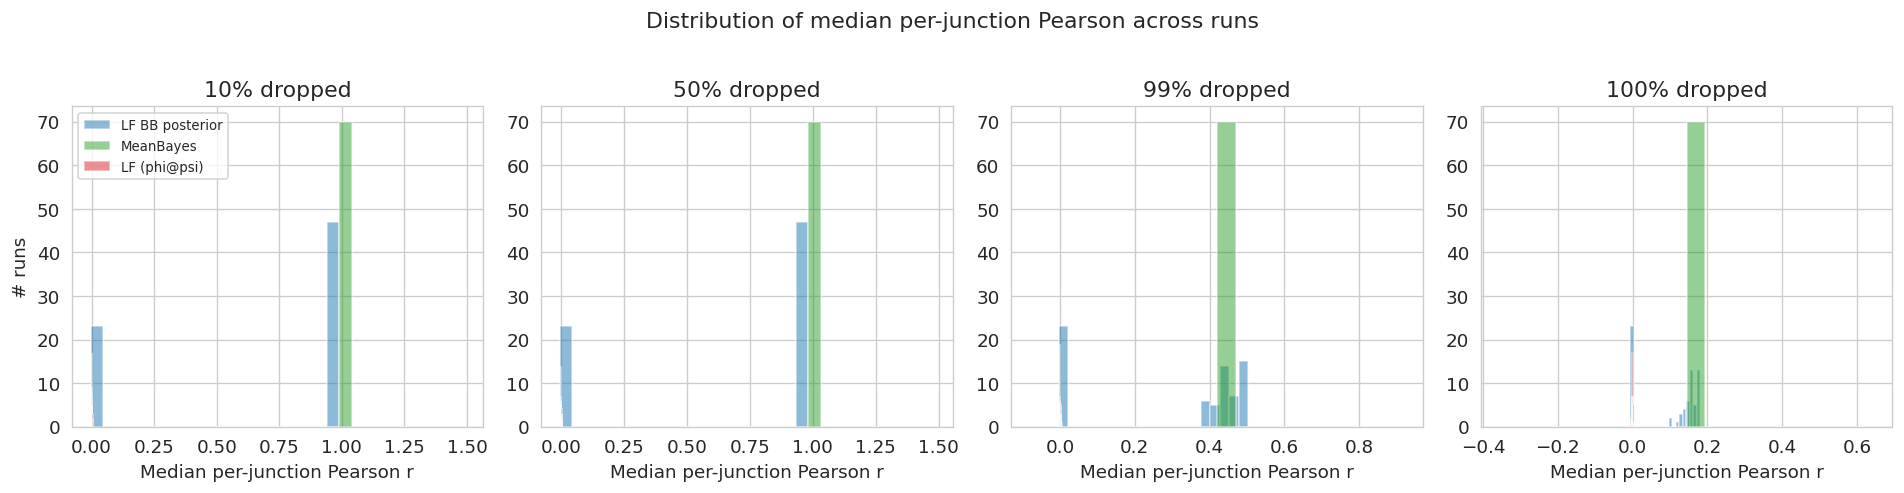

In [9]:
focus_pcts = [10, 50, 99, 100]
fig, axes = plt.subplots(1, len(focus_pcts), figsize=(16, 4), sharey=False)

for ax, pct in zip(axes, focus_pcts):
    sub = all_df[all_df['downsampling_pct'] == pct]
    for col, color in [('median_pearson_lf_bb', '#1f77b4'),
                        ('median_pearson_mb',    '#2ca02c'),
                        ('median_pearson_lf',    '#d62728')]:
        vals = sub[col].dropna()
        ax.hist(vals, bins=20, alpha=0.5, color=color,
                label=METHOD_LABELS[col].replace('LeafletFA ', 'LF '))
    ax.set_title(f'{pct}% dropped')
    ax.set_xlabel('Median per-junction Pearson r')
    if ax == axes[0]:
        ax.set_ylabel('# runs')
        ax.legend(fontsize=8)

plt.suptitle('Distribution of median per-junction Pearson across runs', y=1.02)
plt.tight_layout()
plt.savefig(f'{EVAL_DIR}/fig_pearson_distribution.pdf', bbox_inches='tight')
plt.show()

## 9. Summary table

In [10]:
summary_cols = ['median_pearson_lf', 'median_pearson_lf_bb', 'median_pearson_mb',
                'frac_r_gt_03_lf_bb', 'frac_r_gt_03_mb', 'frac_r_gt_05_lf_bb']
print('=== Median across all 70 runs (dataset=all) ===')
tbl = all_df.groupby('downsampling_pct')[summary_cols].median().round(4)
tbl.index.name = 'pct_dropped'
print(tbl.to_string())

print('\n=== At 99% dropout: lf_bb advantage over mb by K ===')
d99 = all_df[all_df['downsampling_pct'] == 99].copy()
d99['advantage'] = d99['median_pearson_lf_bb'] - d99['median_pearson_mb']
print(d99.groupby('K')[['median_pearson_lf_bb','median_pearson_mb','advantage']].median().round(4).to_string())

=== Median across all 70 runs (dataset=all) ===
             median_pearson_lf  median_pearson_lf_bb  median_pearson_mb  frac_r_gt_03_lf_bb  frac_r_gt_03_mb  frac_r_gt_05_lf_bb
pct_dropped                                                                                                                     
10                         0.0                0.9895             0.9902              0.9995           0.9995              0.9995
25                         0.0                0.9872             0.9882              0.9995           0.9995              0.9995
50                         0.0                0.9799             0.9821              0.9995           0.9995              0.9993
75                         0.0                0.9566             0.9636              0.9990           0.9988              0.9943
90                         0.0                0.8784             0.8941              0.9935           0.9931              0.9772
99                         0.0                0.4